## **GPU decoding with Rumi**

[Rumi](https://asterisk.coop/rumi/) is a raster format for training data, and every frame in a `.rumi` file is a GeoZL frame. This notebook stores a Sentinel-2 crop as a `.rumi` file, reads a window straight into a CUDA tensor, and checks it against the CPU reader. Pick a GPU runtime in Colab before running it, under Runtime and Change runtime type.

In [ ]:
%pip install -q -U geozl rumi-eo rasterio

In [1]:
from pathlib import Path

import geozl
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import rumi
import torch
from matplotlib.patches import Rectangle
from rasterio.windows import Window

assert torch.cuda.is_available(), "Select a GPU runtime in Colab"
print("Rumi", rumi.__version__)
print("GeoZL", geozl.__version__)
print("GPU", torch.cuda.get_device_name(0))

Rumi 0.30.0
GeoZL 0.32.0
GPU NVIDIA A100 80GB PCIe


### **A Sentinel-2 crop**

Four 10 m bands, blue, green, red and near infrared, from a clear Sentinel-2 L2A scene of 8 August 2025 over Lake Annecy in the French Alps. They come from the [public copy on AWS](https://registry.opendata.aws/sentinel-2-l2a-cogs/), 512×512 pixels of uint16 reflectance.

In [2]:
base = ("https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/"
        "31/T/GL/2025/8/S2A_31TGL_20250808_0_L2A/")
BANDS = ["B02", "B03", "B04", "B08"]

bands = []
for band in BANDS:
    with rasterio.open(base + band + ".tif") as src:
        bands.append(src.read(1, window=Window(4364, 1628, 512, 512)))
data = np.stack(bands)
print(data.shape, data.dtype, f"{data.nbytes/1e6:.1f} MB")

(4, 512, 512) uint16 2.1 MB


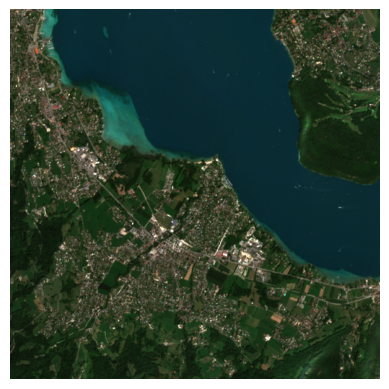

In [3]:
def rgb(x):
    """Red, green and blue bands as an image, stretched for display."""
    return np.clip(np.moveaxis(x[[2, 1, 0]], 0, -1) / 3000, 0, 1)


plt.imshow(rgb(data))
plt.axis("off")
plt.show()

### **Write a .rumi file**

`rumi.frames` cuts the image into 128×128 tiles. The pattern `b (row h) (col w) -> row col (b h w)` keeps the four bands of a tile together in one frame, so this image becomes 16 frames ([frames in the spec](https://github.com/asterisk-labs/rumi/blob/main/SPEC.md#frames)).

Each frame is compressed with `planar>zigzag>lanes`. The GPU decodes a frame whose last step is PFOR or PivCo, and `lanes` ends in one of the two. Any other frame decodes on the CPU and is copied over, as [what runs on the GPU](https://asterisk.coop/geozl/api-gpu.html#routing) explains.

In [4]:
frames = rumi.frames(
    data,
    "b (row h) (col w) -> row col (b h w)",
    tile_size=128,
)
for frame in frames:
    graph = geozl.graph(frame.data, "planar>zigzag>lanes")
    frame.compressed = geozl.compress(frame.data, graph=graph)

path, header = rumi.write(
    Path("annecy.rumi"),
    frames,
    bands=["B2", "B3", "B4", "B8"],
    time=["2025-08-08"],
)
size = path.stat().st_size
print(path, f"{size:,} bytes", f"{data.nbytes/size:.2f}x")

annecy.rumi 1,149,819 bytes 1.82x


### **Read a window into CUDA**

`rumi.read` takes bands and a window given as row, column, height and width. Rumi parses the header and plans the read on the CPU, and only the frames under the window are fetched. GeoZL then decodes them on the GPU and writes the samples into a PyTorch tensor on `cuda:0`.

[How Rumi reads](https://asterisk.coop/rumi/how-rumi-reads.html) follows one read from end to end, and [From compressed bytes to a GPU tensor](https://asterisk.coop/geozl/gpu-internals.html) covers the GPU side. The `cpu()` call below is only for the check against the CPU reader.

In [5]:
selection = dict(bands=[2, 3], window=(96, 80, 192, 224))  # B4 and B8
cpu = rumi.read(path, header, **selection)
gpu = rumi.read(
    path,
    header,
    **selection,
    framework="torch",
    device="cuda:0",
)

assert gpu.is_cuda
np.testing.assert_array_equal(gpu.cpu().numpy(), cpu)
print(gpu.shape, gpu.dtype, gpu.device)

torch.Size([2, 192, 224]) torch.uint16 cuda:0


The tensor is ordinary PyTorch, so work on it stays on the GPU. Here red and near infrared give NDVI, which is high over vegetation and below zero over water. The window crosses nine of the 16 frames.

In [6]:
red, nir = gpu.float()
ndvi = (nir - red) / (nir + red).clamp(min=1)
print(ndvi.device, f"{ndvi.min():.2f} to {ndvi.max():.2f}")

cuda:0 -0.98 to 0.94


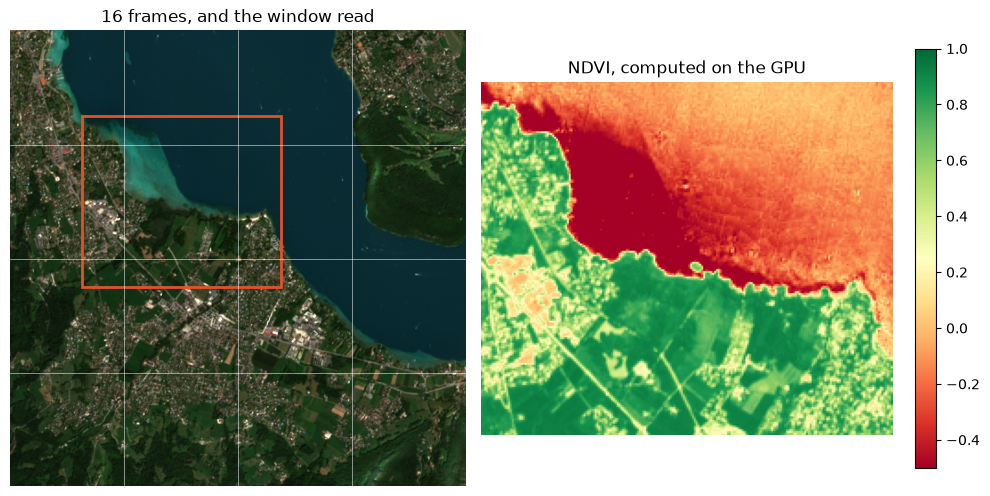

In [7]:
#@title **The window on the image, and its NDVI**

row, col, height, width = selection["window"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 5))

left.imshow(rgb(data))
for k in range(128, 512, 128):
    left.axhline(k, color="white", lw=0.6, alpha=0.6)
    left.axvline(k, color="white", lw=0.6, alpha=0.6)
left.add_patch(Rectangle((col, row), width, height, fill=False, ec="#E0532A", lw=2))
left.set_title("16 frames, and the window read")
left.axis("off")

im = right.imshow(ndvi.cpu(), cmap="RdYlGn", vmin=-0.5, vmax=1)
right.set_title("NDVI, computed on the GPU")
right.axis("off")
fig.colorbar(im, ax=right, fraction=0.046)
plt.tight_layout()
plt.show()

### **Batch windows**

`read_many` reads windows from several files in one call and stacks them into one batch on the same device, which is what a training data loader needs. Here both windows come from the same file. The Rumi [README](https://github.com/asterisk-labs/rumi#quick-start) shows the other options, such as JAX tensors and the MPS device on Apple silicon.

In [8]:
windows = [
    (0, 0, 128, 128),
    (256, 256, 128, 128),
]
batch = rumi.read_many(
    [path, path],
    [header, header],
    windows=windows,
    framework="torch",
    device="cuda:0",
)

expected = np.stack([
    data[:, row:row + height, col:col + width]
    for row, col, height, width in windows
])
assert batch.is_cuda
np.testing.assert_array_equal(batch.cpu().numpy(), expected)
print(batch.shape, batch.dtype, batch.device)

torch.Size([2, 4, 128, 128]) torch.uint16 cuda:0


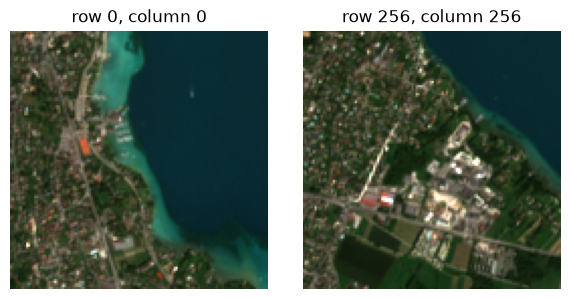

In [9]:
#@title **The two windows in the batch**

fig, axes = plt.subplots(1, len(windows), figsize=(6, 3))
for ax, chip, (row, col, _, _) in zip(axes, batch.cpu().numpy(), windows, strict=True):
    ax.imshow(rgb(chip))
    ax.set_title(f"row {row}, column {col}")
    ax.axis("off")
plt.tight_layout()
plt.show()

GeoZL's [GPU decoding guide](https://asterisk.coop/geozl/api-gpu.html) describes the C API that Rumi binds, and [What a GPU wants from a format](https://asterisk.coop/geozl/gpu-codecs.html) explains why PFOR and PivCo decode well there. Rumi's code is in its [repository](https://github.com/asterisk-labs/rumi), and its [spec](https://github.com/asterisk-labs/rumi/blob/main/SPEC.md) describes the file layout.

---

<p align="center">Part of Earth Compress, led by Asterisk Labs and the National Oceanography Centre and funded by ARIA.</p>

<p align="center">
  <a href="https://asterisk.coop"><img src="https://asterisk.coop/geozl/assets/svg/partners/asterisk.svg" alt="Asterisk Labs" height="22"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://asterisk.coop/project-pages/earth-compress.html"><img src="https://asterisk.coop/geozl/assets/svg/partners/earth-compress.svg" alt="Earth Compress" height="24"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://noc.ac.uk/"><img src="https://asterisk.coop/geozl/assets/svg/partners/noc.svg" alt="National Oceanography Centre" height="34"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://www.aria.org.uk/"><img src="https://asterisk.coop/geozl/assets/svg/partners/aria.svg" alt="ARIA" height="32"></a>
</p>